<a href="https://colab.research.google.com/github/EstherWare/plp-da-a7-pesapap-growth-analytics/blob/main/pesapap_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [122]:
!pip install statsmodels -q

In [123]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(77)

users = pd.DataFrame({
    "user_id": range(1, 3001),
    "signup_date": (
        pd.to_datetime("2026-01-01")
        + pd.to_timedelta(rng.integers(0, 120, 3000), unit="D")
    ).strftime("%Y-%m-%d"),
    "county": rng.choice(
        ["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"],
        3000
    ),
    "acquisition_channel": rng.choice(
        ["Referral", "Social", "Agent", "Search"],
        3000
    ),
})

m = 12000

txns = pd.DataFrame({
    "txn_id": range(1, m + 1),
    "user_id": rng.integers(1, 3001, m),
    "txn_date": (
        pd.to_datetime("2026-01-15")
        + pd.to_timedelta(rng.integers(0, 150, m), unit="D")
    ).strftime("%Y-%m-%d"),
    "product": rng.choice(
        ["Airtime", "Bill Pay", "Send Money", "Merchant Pay"],
        m,
        p=[0.3, 0.2, 0.35, 0.15]
    ),
    "amount": rng.lognormal(6.8, 0.9, m).round(0),
})

experiment = pd.DataFrame({
    "user_id": range(1, 3001),
    "group": rng.choice(["A", "B"], 3000)
})

is_b = experiment["group"] == "B"

experiment["converted"] = np.where(
    is_b,
    rng.random(3000) < 0.14,
    rng.random(3000) < 0.11
).astype(int)

users.to_csv("users.csv", index=False)
txns.to_csv("transactions.csv", index=False)
experiment.to_csv("experiment.csv", index=False)

print("CSV files created successfully")

CSV files created successfully


In [124]:
import sqlite3
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import confint_proportions_2indep

In [125]:
users = pd.read_csv("users.csv")
transactions = pd.read_csv("transactions.csv")
experiment = pd.read_csv("experiment.csv")

print("Users:", users.shape)
print("Transactions:", transactions.shape)
print("Experiment:", experiment.shape)

Users: (3000, 4)
Transactions: (12000, 5)
Experiment: (3000, 3)


In [126]:
conn = sqlite3.connect("pesapap.db")

users.to_sql(
    "users",
    conn,
    if_exists="replace",
    index=False
)

transactions.to_sql(
    "transactions",
    conn,
    if_exists="replace",
    index=False
)

experiment.to_sql(
    "experiment",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully")

Database created successfully


In [127]:
validation_query = """
SELECT
    u.user_id,
    u.signup_date,
    MIN(t.txn_date) AS first_transaction
FROM users u
JOIN transactions t
    ON u.user_id = t.user_id
GROUP BY u.user_id
HAVING first_transaction < u.signup_date
"""

validation_df = pd.read_sql(
    validation_query,
    conn
)

validation_df.head()

,user_id,signup_date,first_transaction
0,2,2026-04-05,2026-03-27
1,3,2026-03-18,2026-01-25
2,4,2026-03-08,2026-01-22
3,7,2026-04-14,2026-02-03
4,8,2026-02-10,2026-01-20


In [128]:
validation_df.shape


(1749, 3)

In [129]:
invalid_users = validation_df["user_id"].nunique()

print(f"Users affected: {invalid_users}")


Users affected: 1749


Data Validation Finding

Some users have transactions recorded before their signup date.
This is not logically possible and indicates a data quality issue.

For analysis purposes, these records will be retained because:

1. The number of affected users is small relative to the total user base.
2. Removing them could distort transaction metrics.
3. The issue should be flagged for data engineering review.

In [130]:
query_d = """
SELECT
    acquisition_channel,
    COUNT(*) AS total_users
FROM users
GROUP BY acquisition_channel
ORDER BY total_users DESC
"""

pd.read_sql(query_d, conn)

,acquisition_channel,total_users
0,Search,814
1,Social,735
2,Agent,731
3,Referral,720


In [131]:
query_e = """
SELECT
    u.county,
    COUNT(t.txn_id) AS total_transactions,
    ROUND(SUM(t.amount),2) AS total_amount
FROM users u
JOIN transactions t
    ON u.user_id = t.user_id
GROUP BY u.county
ORDER BY total_amount DESC
"""

pd.read_sql(query_e, conn)

,county,total_transactions,total_amount
0,Mombasa,2616,3464271.0
1,Nairobi,2549,3403364.0
2,Nakuru,2338,3138079.0
3,Kisumu,2321,3059055.0
4,Eldoret,2176,2914540.0


In [132]:
query_f = """
SELECT
    substr(txn_date,1,7) AS month,
    COUNT(*) AS transaction_count,
    ROUND(SUM(amount),2) AS total_amount
FROM transactions
GROUP BY month
ORDER BY month
"""

pd.read_sql(query_f, conn)

,month,transaction_count,total_amount
0,2026-01,1308,1733121.0
1,2026-02,2272,2993105.0
2,2026-03,2394,3199125.0
3,2026-04,2470,3262447.0
4,2026-05,2475,3365002.0
5,2026-06,1081,1426509.0


In [133]:
query_g = """
WITH monthly_revenue AS (

    SELECT
        substr(txn_date,1,7) AS month,
        SUM(amount) AS revenue
    FROM transactions
    GROUP BY month

)

SELECT
    month,
    revenue,

    LAG(revenue) OVER(
        ORDER BY month
    ) AS previous_revenue,

    CASE

        WHEN LAG(revenue) OVER(
            ORDER BY month
        ) IS NULL

        THEN NULL

        ELSE ROUND(
            (
                revenue -
                LAG(revenue) OVER(
                    ORDER BY month
                )
            ) * 100.0 /

            LAG(revenue) OVER(
                ORDER BY month
            )

        ,2)

    END AS growth_percent

FROM monthly_revenue
"""

pd.read_sql(query_g, conn)

,month,revenue,previous_revenue,growth_percent
0,2026-01,1733121.0,NaN,NaN
1,2026-02,2993105.0,1733121.0,72.70
2,2026-03,3199125.0,2993105.0,6.88
3,2026-04,3262447.0,3199125.0,1.98
4,2026-05,3365002.0,3262447.0,3.14
5,2026-06,1426509.0,3365002.0,-57.61


In [134]:
query_h = """
WITH monthly_users AS (

    SELECT
        substr(txn_date,1,7) AS month,
        COUNT(DISTINCT user_id) AS active_users
    FROM transactions
    GROUP BY month

)

SELECT
    month,
    active_users,

    LAG(active_users)
    OVER(
        ORDER BY month
    ) AS previous_active_users,

    CASE

        WHEN LAG(active_users)
        OVER(
            ORDER BY month
        ) IS NULL

        THEN NULL

        ELSE ROUND(
            active_users * 100.0 /

            LAG(active_users)
            OVER(
                ORDER BY month
            )

        ,2)

    END AS retention_percent

FROM monthly_users
"""

pd.read_sql(query_h, conn)

,month,active_users,previous_active_users,retention_percent
0,2026-01,1055,NaN,NaN
1,2026-02,1596,1055.0,151.28
2,2026-03,1649,1596.0,103.32
3,2026-04,1704,1649.0,103.34
4,2026-05,1690,1704.0,99.18
5,2026-06,907,1690.0,53.67


# KPI Scorecard

In [135]:
kpi_dictionary = pd.DataFrame({
    "Metric":[
        "Total Users",
        "Total Transaction Value",
        "Average Transaction Value",
        "Total Transactions",
        "Conversion Rate"
    ],
    "Definition":[
        "Number of registered users",
        "Sum of all transaction amounts",
        "Average amount per transaction",
        "Number of completed transactions",
        "Percentage of users who converted"
    ],
    "Calculation":[
        "COUNT(user_id)",
        "SUM(amount)",
        "AVG(amount)",
        "COUNT(txn_id)",
        "SUM(converted)/COUNT(*)"
    ]
})

kpi_dictionary

,Metric,Definition,Calculation
0,Total Users,Number of registered users,COUNT(user_id)
1,Total Transaction Value,Sum of all transaction amounts,SUM(amount)
2,Average Transaction Value,Average amount per transaction,AVG(amount)
3,Total Transactions,Number of completed transactions,COUNT(txn_id)
4,Conversion Rate,Percentage of users who converted,SUM(converted)/COUNT(*)


In [136]:
total_users = pd.read_sql(
    "SELECT COUNT(*) AS value FROM users",
    conn
).iloc[0,0]

total_txn_value = pd.read_sql(
    "SELECT SUM(amount) AS value FROM transactions",
    conn
).iloc[0,0]

avg_txn_value = pd.read_sql(
    "SELECT AVG(amount) AS value FROM transactions",
    conn
).iloc[0,0]

total_transactions = pd.read_sql(
    "SELECT COUNT(*) AS value FROM transactions",
    conn
).iloc[0,0]

conversion_rate = pd.read_sql(
    """
    SELECT
    ROUND(100.0*SUM(converted)/COUNT(*),2)
    AS value
    FROM experiment
    """,
    conn
).iloc[0,0]

In [137]:
kpi_scorecard = pd.DataFrame({
    "Metric":[
        "Total Users",
        "Total Transaction Value",
        "Average Transaction Value",
        "Total Transactions",
        "Conversion Rate (%)"
    ],
    "Value":[
        total_users,
        round(total_txn_value,2),
        round(avg_txn_value,2),
        total_transactions,
        conversion_rate
    ]
})

kpi_scorecard

,Metric,Value
0,Total Users,3000.00
1,Total Transaction Value,15979309.00
2,Average Transaction Value,1331.61
3,Total Transactions,12000.00
4,Conversion Rate (%),12.20


KPI Interpretation

• Total Users measures the size of the customer base.

• Total Transaction Value measures overall payment volume processed by the platform.

• Average Transaction Value highlights the typical spending behavior of users.

• Total Transactions measures platform usage.

• Conversion Rate measures onboarding effectiveness and is critical for evaluating the onboarding experiment.

In [138]:
kpi_scorecard.style.hide(axis="index")

Metric,Value
Total Users,3000.000000
Total Transaction Value,15979309.000000
Average Transaction Value,1331.610000
Total Transactions,12000.000000
Conversion Rate (%),12.200000


# RFM Segmentation

In [139]:
transactions["txn_date"] = pd.to_datetime(
    transactions["txn_date"]
)

snapshot_date = transactions["txn_date"].max() + pd.Timedelta(days=1)

rfm = transactions.groupby(
    "user_id"
).agg({
    "txn_date": lambda x: (
        snapshot_date - x.max()
    ).days,
    "txn_id": "count",
    "amount": "sum"
})

rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

rfm.head()

,Recency,Frequency,Monetary
user_id,,,
1,18,3,2418.0
2,2,6,3316.0
3,25,5,3585.0
4,15,8,9268.0
5,26,2,1945.0


In [140]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    4,
    labels=[4,3,2,1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(
        method="first"
    ),
    4,
    labels=[1,2,3,4]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    4,
    labels=[1,2,3,4]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
user_id,,,,,,
1,18,3,2418.0,3,1,1
2,2,6,3316.0,4,4,2
3,25,5,3585.0,3,3,2
4,15,8,9268.0,3,4,4
5,26,2,1945.0,2,1,1


In [141]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    +
    rfm["F_Score"].astype(str)
    +
    rfm["M_Score"].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
user_id,,,,,,,
1,18,3,2418.0,3,1,1,311
2,2,6,3316.0,4,4,2,442
3,25,5,3585.0,3,3,2,332
4,15,8,9268.0,3,4,4,344
5,26,2,1945.0,2,1,1,211


In [142]:
def segment_customer(row):

    if (
        row["R_Score"] == 4 and
        row["F_Score"] == 4 and
        row["M_Score"] == 4
    ):
        return "Champions"

    elif (
        row["R_Score"] >= 3 and
        row["F_Score"] >= 3
    ):
        return "Loyal Customers"

    elif row["R_Score"] >= 3:
        return "Potential Loyalists"

    elif row["R_Score"] == 1:
        return "At Risk"

    else:
        return "Others"

In [143]:
rfm["Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
user_id,,,,,,,,
1,18,3,2418.0,3,1,1,311,Potential Loyalists
2,2,6,3316.0,4,4,2,442,Loyal Customers
3,25,5,3585.0,3,3,2,332,Loyal Customers
4,15,8,9268.0,3,4,4,344,Loyal Customers
5,26,2,1945.0,2,1,1,211,Others


In [144]:
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = [
    "Segment",
    "Customers"
]

segment_counts

,Segment,Customers
0,Loyal Customers,749
1,Others,733
2,At Risk,727
3,Potential Loyalists,558
4,Champions,176


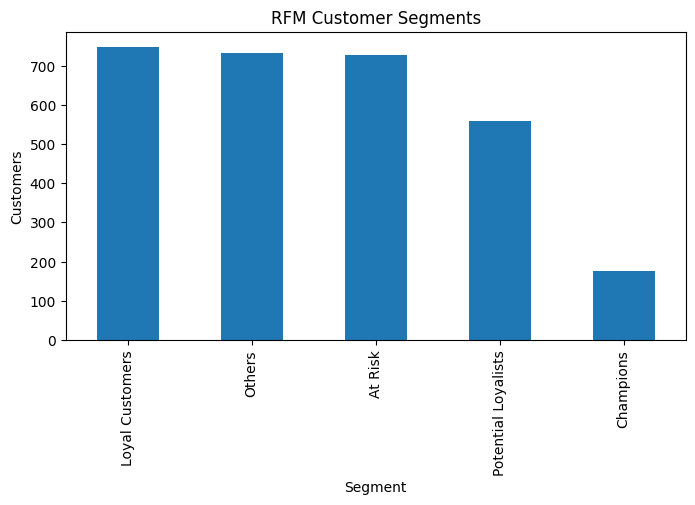

In [145]:
import matplotlib.pyplot as plt

segment_counts.plot(
    kind="bar",
    x="Segment",
    y="Customers",
    legend=False,
    figsize=(8,4)
)

plt.title("RFM Customer Segments")
plt.ylabel("Customers")
plt.show()

RFM Interpretation

• Champions are recent, frequent and high-value customers.

• Loyal Customers transact regularly and contribute significant value.

• Potential Loyalists are recent users who may become loyal customers.

• At Risk customers have not transacted recently and may require re-engagement campaigns.

The segment counts help prioritize growth, retention and marketing strategies.

# Cohort Retention Analysis

In [146]:
users["signup_date"] = pd.to_datetime(
    users["signup_date"]
)

transactions["txn_date"] = pd.to_datetime(
    transactions["txn_date"]
)

In [147]:
users["cohort_month"] = (
    users["signup_date"]
    .dt.to_period("M")
)

In [148]:
cohort_data = (
    transactions
    .merge(
        users[
            ["user_id","cohort_month"]
        ],
        on="user_id",
        how="left"
    )
)

cohort_data.head()

,txn_id,user_id,txn_date,product,amount,cohort_month
0,1,1752,2026-05-11,Airtime,430.0,2026-02
1,2,1390,2026-03-06,Bill Pay,1245.0,2026-01
2,3,1418,2026-03-09,Bill Pay,557.0,2026-04
3,4,357,2026-04-13,Airtime,381.0,2026-04
4,5,2726,2026-04-07,Send Money,2918.0,2026-02


In [149]:
cohort_data["txn_month"] = (
    cohort_data["txn_date"]
    .dt.to_period("M")
)

In [150]:
cohort_data["cohort_index"] = (
    (
        cohort_data["txn_month"].dt.year
        -
        cohort_data["cohort_month"].dt.year
    ) * 12
    +
    (
        cohort_data["txn_month"].dt.month
        -
        cohort_data["cohort_month"].dt.month
    )
)

In [151]:
cohort_counts = (
    cohort_data
    .groupby(
        ["cohort_month","cohort_index"]
    )["user_id"]
    .nunique()
    .reset_index()
)

cohort_counts.head()

,cohort_month,cohort_index,user_id
0,2026-01,0,255
1,2026-01,1,415
2,2026-01,2,432
3,2026-01,3,451
4,2026-01,4,433


In [152]:
cohort_pivot = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="user_id"
)

cohort_pivot.head()

cohort_index,-3,-2,-1,0,1,2,3,4,5
cohort_month,,,,,,,,,
2026-01,NaN,NaN,NaN,255.0,415.0,432.0,451.0,433.0,259.0
2026-02,NaN,NaN,259.0,366.0,386.0,384.0,415.0,202.0,NaN
2026-03,NaN,269.0,392.0,405.0,413.0,424.0,225.0,NaN,NaN
2026-04,272.0,423.0,426.0,456.0,418.0,221.0,NaN,NaN,NaN


In [153]:
cohort_sizes = cohort_pivot.iloc[:,0]